## EDA

In [152]:
# Importing necessary libraries
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler,MinMaxScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.ensemble import RandomForestClassifier,ExtraTreesClassifier,GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from imblearn.over_sampling import SMOTE,SMOTEN,SMOTENC


In [153]:
# loading the Data
df = pd.read_csv(r'C:\Devesh\Credit_Risk_Assessment_ML_Model\data\data.csv')
df.sample(frac=1).head(20)

,estimate_of_risk,months_since_first_trade,months_since_last_trade,average_duration_of_resolution,number_of_satisfactory_trades,nr_trades_insolvent_for_over_60_days,nr_trades_insolvent_for_over_90_days,percentage_of_legal_trades,months_since_last_illegal_trade,maximum_illegal_trades_over_last_year,...,months_since_last_inquiry_not_recent,nr_inquiries_in_last_6_months,nr_inquiries_in_last_6_months_not_recent,net_fraction_of_revolving_burden,net_fraction_of_installment_burden,nr_revolving_trades_with_balance,nr_installment_trades_with_balance,nr_banks_with_high_ratio,percentage_trades_with_balance,is_at_risk
5748,81,212,6,84,22,0,0,95,16,6,...,0,0,0,5,-8,2,2,0,40,0
3673,87,294,8,93,35,0,0,100,-7,7,...,0,1,1,2,71,1,4,0,24,0
5629,71,128,3,68,12,1,1,85,27,6,...,0,0,0,80,99,6,2,1,80,1
2476,73,133,0,58,2,1,1,100,-7,6,...,-7,9,9,18,-8,3,-8,0,75,1
5101,84,166,20,65,24,0,0,100,-7,7,...,19,0,0,2,52,2,6,0,62,0
5030,71,216,27,70,16,0,0,94,20,6,...,7,0,0,75,-8,2,1,1,60,0
9635,73,126,1,39,24,0,0,96,14,6,...,3,2,1,14,97,2,4,0,67,1
9284,55,211,48,103,9,5,5,69,3,4,...,0,3,2,1,-8,1,-8,0,50,1
3468,73,273,2,135,10,2,1,85,19,6,...,4,1,1,5,100,3,1,0,50,1
3330,81,166,4,60,20,0,0,100,-7,7,...,5,1,1,0,3,1,3,0,25,1


In [154]:
'''
This data too many Inconsistencies
data have too many rows with this format: -9,-9,-9..... 

therefore, before eda remove all rows that have -9 present in any feature
'''
# Removes any row where at least one column has a value of -9
df = df[~(df < 0).any(axis=1)]  
df


,estimate_of_risk,months_since_first_trade,months_since_last_trade,average_duration_of_resolution,number_of_satisfactory_trades,nr_trades_insolvent_for_over_60_days,nr_trades_insolvent_for_over_90_days,percentage_of_legal_trades,months_since_last_illegal_trade,maximum_illegal_trades_over_last_year,...,months_since_last_inquiry_not_recent,nr_inquiries_in_last_6_months,nr_inquiries_in_last_6_months_not_recent,net_fraction_of_revolving_burden,net_fraction_of_installment_burden,nr_revolving_trades_with_balance,nr_installment_trades_with_balance,nr_banks_with_high_ratio,percentage_trades_with_balance,is_at_risk
3,66,169,1,73,28,1,1,93,76,6,...,0,5,4,72,83,6,4,3,91,1
5,59,137,11,78,31,0,0,91,1,4,...,0,0,0,62,93,12,4,3,94,1
6,54,88,7,37,25,0,0,92,9,4,...,0,4,4,89,76,7,7,2,100,0
7,68,148,7,65,17,0,0,83,31,6,...,0,0,0,28,48,2,2,2,40,0
9,61,79,4,36,19,0,0,95,5,4,...,0,6,6,31,86,5,3,1,62,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10436,82,115,4,58,24,1,0,96,50,6,...,4,1,1,2,52,1,4,0,71,0
10439,79,224,4,84,61,0,0,97,28,6,...,2,4,4,1,98,5,2,1,32,0
10443,76,353,2,92,40,0,0,95,69,6,...,4,1,1,33,45,2,2,0,80,0
10449,57,176,4,87,18,0,0,89,2,4,...,4,1,1,93,72,5,3,1,100,0


In [155]:
# Dropping unwanted columns
df = df.drop(columns=["estimate_of_risk","nr_trades_insolvent_for_over_90_days","maximum_illegal_trades","nr_total_trades"],errors='ignore')
df.head()

,months_since_first_trade,months_since_last_trade,average_duration_of_resolution,number_of_satisfactory_trades,nr_trades_insolvent_for_over_60_days,percentage_of_legal_trades,months_since_last_illegal_trade,maximum_illegal_trades_over_last_year,nr_trades_initiated_in_last_year,percentage_of_installment_trades,months_since_last_inquiry_not_recent,nr_inquiries_in_last_6_months,nr_inquiries_in_last_6_months_not_recent,net_fraction_of_revolving_burden,net_fraction_of_installment_burden,nr_revolving_trades_with_balance,nr_installment_trades_with_balance,nr_banks_with_high_ratio,percentage_trades_with_balance,is_at_risk
3,169,1,73,28,1,93,76,6,3,57,0,5,4,72,83,6,4,3,91,1
5,137,11,78,31,0,91,1,4,1,47,0,0,0,62,93,12,4,3,94,1
6,88,7,37,25,0,92,9,4,3,58,0,4,4,89,76,7,7,2,100,0
7,148,7,65,17,0,83,31,6,1,44,0,0,0,28,48,2,2,2,40,0
9,79,4,36,19,0,95,5,4,3,26,0,6,6,31,86,5,3,1,62,1


In [156]:
# checking the columns
df.columns

Index(['months_since_first_trade', 'months_since_last_trade',
       'average_duration_of_resolution', 'number_of_satisfactory_trades',
       'nr_trades_insolvent_for_over_60_days', 'percentage_of_legal_trades',
       'months_since_last_illegal_trade',
       'maximum_illegal_trades_over_last_year',
       'nr_trades_initiated_in_last_year', 'percentage_of_installment_trades',
       'months_since_last_inquiry_not_recent', 'nr_inquiries_in_last_6_months',
       'nr_inquiries_in_last_6_months_not_recent',
       'net_fraction_of_revolving_burden',
       'net_fraction_of_installment_burden',
       'nr_revolving_trades_with_balance',
       'nr_installment_trades_with_balance', 'nr_banks_with_high_ratio',
       'percentage_trades_with_balance', 'is_at_risk'],
      dtype='str')

In [157]:
# checking info of data
df.info()

<class 'pandas.DataFrame'>
Index: 2502 entries, 3 to 10455
Data columns (total 20 columns):
 #   Column                                    Non-Null Count  Dtype
---  ------                                    --------------  -----
 0   months_since_first_trade                  2502 non-null   int64
 1   months_since_last_trade                   2502 non-null   int64
 2   average_duration_of_resolution            2502 non-null   int64
 3   number_of_satisfactory_trades             2502 non-null   int64
 4   nr_trades_insolvent_for_over_60_days      2502 non-null   int64
 5   percentage_of_legal_trades                2502 non-null   int64
 6   months_since_last_illegal_trade           2502 non-null   int64
 7   maximum_illegal_trades_over_last_year     2502 non-null   int64
 8   nr_trades_initiated_in_last_year          2502 non-null   int64
 9   percentage_of_installment_trades          2502 non-null   int64
 10  months_since_last_inquiry_not_recent      2502 non-null   int64
 11  nr_inq

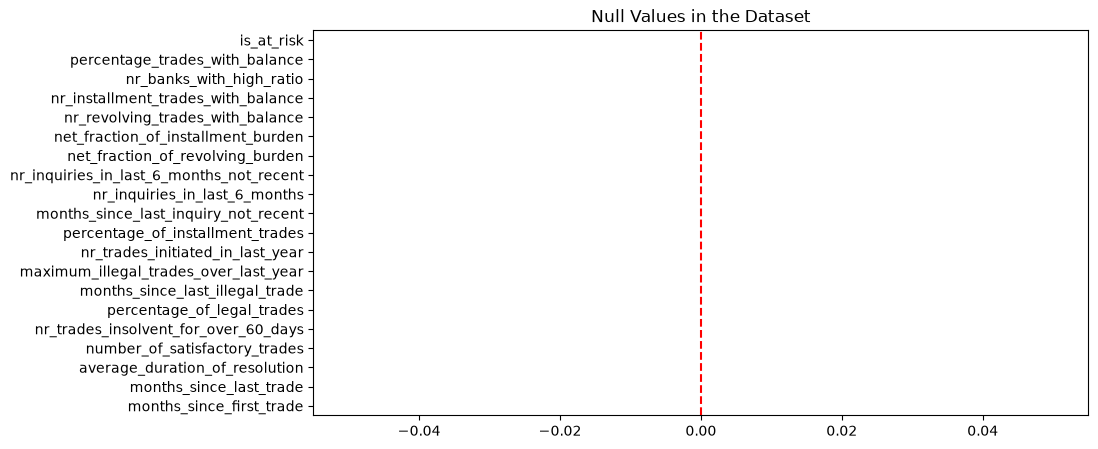

In [158]:
# checking null 
plt.figure(figsize=(10,5))
df.isnull().sum().plot(kind='barh')
plt.title('Null Values in the Dataset')
plt.axvline(0,color='r',linestyle='--')
plt.show()

In [159]:
# checking  duplicate values
df.duplicated().sum()
# no duplicates

np.int64(0)

<Axes: >

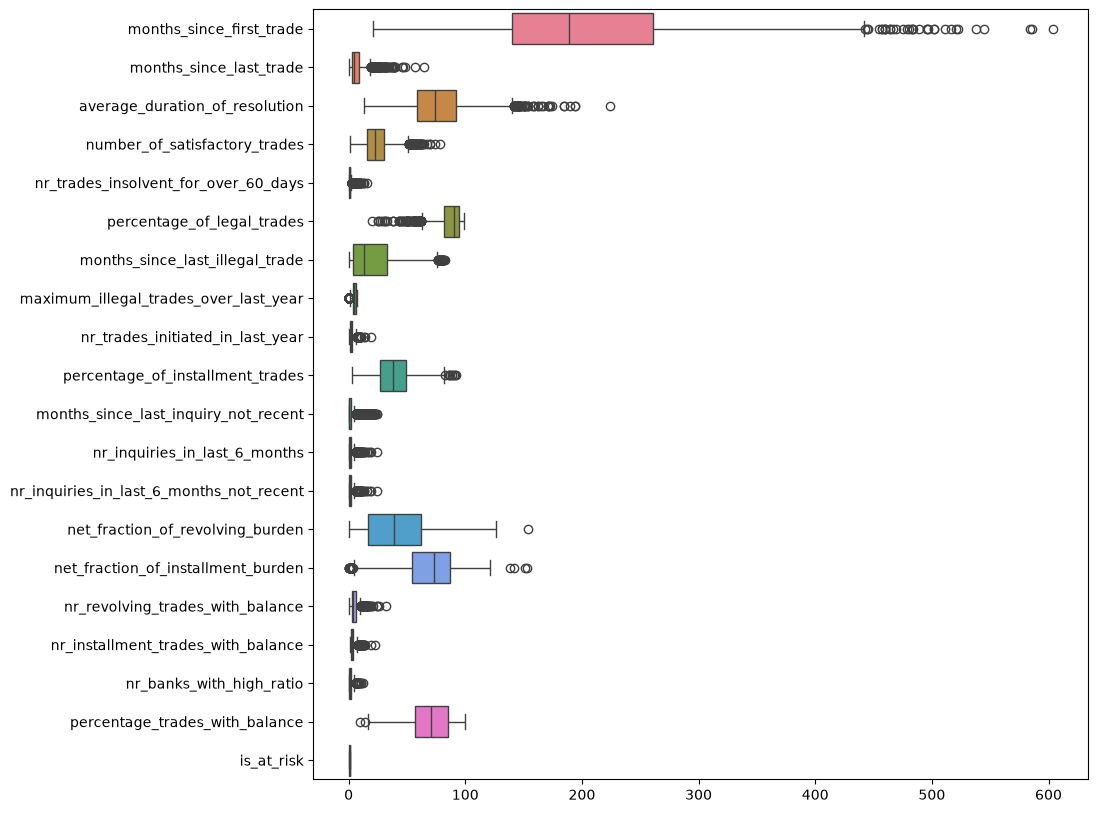

In [160]:
# Checking outlieras using Boxplot
plt.figure(figsize=(10,10))
sns.boxplot(df,orient='h')

In [161]:
# outliers detection using code
from collections import OrderedDict
outlier = []
for i in df.columns:
    Q1 = df[i].quantile(0.25)
    Q3 = df[i].quantile(0.75)
    
    IQR = Q3-Q1
    
    LW = Q1 - 1.5*IQR
    UW = Q3 + 1.5*IQR
    
    order = OrderedDict({
        'feature': df[i].name,
        'Lw':LW,
        'UW':UW,
        'no. of Outlier': ((df[i] < LW) | (df[i] > UW)).sum(),
        'outlier %': (((df[i] < LW) | (df[i] > UW)).sum()/len(df[i]))*100,
    })
    outlier.append(order)
outlier_report = pd.DataFrame(outlier)
outlier_report

,feature,Lw,UW,no. of Outlier,outlier %
0,months_since_first_trade,-41.500,442.500,34,1.358913
1,months_since_last_trade,-6.000,18.000,157,6.274980
2,average_duration_of_resolution,9.500,141.500,57,2.278177
3,number_of_satisfactory_trades,-5.000,51.000,64,2.557954
4,nr_trades_insolvent_for_over_60_days,-1.500,2.500,240,9.592326
5,percentage_of_legal_trades,62.500,114.500,90,3.597122
6,months_since_last_illegal_trade,-39.500,76.500,35,1.398881
7,maximum_illegal_trades_over_last_year,1.000,9.000,136,5.435651
8,nr_trades_initiated_in_last_year,-2.000,6.000,60,2.398082
9,percentage_of_installment_trades,-6.000,82.000,9,0.359712


In [162]:
# Handling outlier by winsorization
from scipy.stats.mstats import winsorize

for i in X.columns:
    df[i] = winsorize(df[i],limits=[0.02,0.02])

In [163]:
# outliers handling
from collections import OrderedDict
outlier = []
for i in df.columns:
    Q1 = df[i].quantile(0.25)
    Q3 = df[i].quantile(0.75)
    
    IQR = Q3-Q1
    
    LW = Q1 - 1.5*IQR
    UW = Q3 + 1.5*IQR
    
    order = OrderedDict({
        'feature': df[i].name,
        'Lw':LW,
        'UW':UW,
        'no. of Outlier': ((df[i] < LW) | (df[i] > UW)).sum(),
        'outlier %': (((df[i] < LW) | (df[i] > UW)).sum()/len(df[i]))*100,
    })
    outlier.append(order)
outlier_report = pd.DataFrame(outlier)
outlier_report

,feature,Lw,UW,no. of Outlier,outlier %
0,months_since_first_trade,-41.500,442.500,0,0.000000
1,months_since_last_trade,-6.000,18.000,157,6.274980
2,average_duration_of_resolution,9.500,141.500,57,2.278177
3,number_of_satisfactory_trades,-5.000,51.000,64,2.557954
4,nr_trades_insolvent_for_over_60_days,-1.500,2.500,240,9.592326
5,percentage_of_legal_trades,62.500,114.500,90,3.597122
6,months_since_last_illegal_trade,-39.500,76.500,0,0.000000
7,maximum_illegal_trades_over_last_year,1.000,9.000,136,5.435651
8,nr_trades_initiated_in_last_year,-2.000,6.000,60,2.398082
9,percentage_of_installment_trades,-6.000,82.000,0,0.000000


In [164]:
# checking Descriptive Stats of data using orderedict
from collections import OrderedDict

stats = []
for i in df.columns:
    order = OrderedDict({
        'Feature':df[i].name,
        'Count':df[i].count(),
        'Min':df[i].min(),
        'Max':df[i].max(),
        'Mean':df[i].mean(),
        'Median':df[i].median(),
        'Q1':df[i].quantile(0.25),
        'Q3':df[i].quantile(0.75),
        'IQR':df[i].quantile(0.75)-df[i].quantile(0.25),
        'Std':df[i].std(),
        'Variance':df[i].var(),
        'Skewness':df[i].skew(),
        'Kurtosis':df[i].kurtosis()
    })
    stats.append(order)
    
report = pd.DataFrame(stats)
report

,Feature,Count,Min,Max,Mean,Median,Q1,Q3,IQR,Std,Variance,Skewness,Kurtosis
0,months_since_first_trade,2502,57,426,204.221023,189.0,140.0,261.00,121.00,88.501666,7832.544892,0.603137,-0.202669
1,months_since_last_trade,2502,1,26,6.913269,5.0,3.0,9.00,6.00,5.817640,33.844934,1.538216,2.047945
2,average_duration_of_resolution,2502,27,143,76.267786,74.0,59.0,92.00,33.00,25.712079,661.110989,0.458246,-0.018330
3,number_of_satisfactory_trades,2502,6,53,24.147082,23.0,16.0,30.00,14.00,10.777341,116.151089,0.607399,0.025683
4,nr_trades_insolvent_for_over_60_days,2502,0,5,0.902078,1.0,0.0,1.00,1.00,1.211535,1.467817,1.658362,2.536803
5,percentage_of_legal_trades,2502,56,98,87.305356,90.0,82.0,95.00,13.00,10.000174,100.003482,-1.311666,1.219416
6,months_since_last_illegal_trade,2502,0,74,21.034772,13.0,4.0,33.00,29.00,20.490116,419.844852,1.064973,0.090722
7,maximum_illegal_trades_over_last_year,2502,0,6,4.719424,5.0,4.0,6.00,2.00,1.597308,2.551394,-1.413705,1.827102
8,nr_trades_initiated_in_last_year,2502,0,7,2.144684,2.0,1.0,3.00,2.00,1.730275,2.993852,0.813145,0.179067
9,percentage_of_installment_trades,2502,12,73,38.310152,38.0,27.0,49.00,22.00,14.889454,221.695851,0.304110,-0.606744


In [165]:
# Splitting data into Taraget and Input
X = df.drop(columns='is_at_risk')
y = df['is_at_risk']



In [166]:
#Splitting into training and testing
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=1)


In [167]:
# scaling
from sklearn.preprocessing import RobustScaler


scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [168]:
# Balancing data
sm = SMOTEN()
X_train_balanced,y_train_balanced = sm.fit_resample(X_train_scaled,y_train)

In [172]:
from sklearn.ensemble import AdaBoostClassifier,GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score,KFold

models = {"LR":LogisticRegression(),
          "DT":DecisionTreeClassifier(),
          "RF":RandomForestClassifier(),
          "ExtraTreesClassifier":ExtraTreesClassifier(),
          "Adaboost":AdaBoostClassifier(),
          "GradientBoost":GradientBoostingClassifier(),
          
          
          
          
          }

for name,model in models.items():
    model.fit(X_train_balanced,y_train_balanced)
    
    y_pred = model.predict(X_test_scaled)
    report = classification_report(y_test,y_pred)
    print(name,"\n",report)
    print()
    
    kf = KFold(n_splits=5, shuffle=True, random_state=1)
    cv = cross_val_score(model,X_train_balanced,y_train_balanced,cv=kf)
    print("CV=",np.mean(cv))
    print()

LR 
               precision    recall  f1-score   support

           0       0.53      0.57      0.54       182
           1       0.74      0.71      0.72       319

    accuracy                           0.66       501
   macro avg       0.63      0.64      0.63       501
weighted avg       0.66      0.66      0.66       501


CV= 0.7340794768611671

DT 
               precision    recall  f1-score   support

           0       0.44      0.48      0.46       182
           1       0.69      0.65      0.67       319

    accuracy                           0.59       501
   macro avg       0.56      0.57      0.56       501
weighted avg       0.60      0.59      0.59       501


CV= 0.6510904134484325

RF 
               precision    recall  f1-score   support

           0       0.54      0.52      0.53       182
           1       0.73      0.75      0.74       319

    accuracy                           0.66       501
   macro avg       0.64      0.63      0.63       501
weighted 

In [174]:

from sklearn.model_selection import RandomizedSearchCV

# 1. Define the parameters you want to test
param_grid = {
    'n_estimators': [50, 100, 200, 300,],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    
}

# 2. Initialize your base model
model = RandomForestClassifier(random_state=42)

# 3. Set up RandomizedSearchCV
search = RandomizedSearchCV(
    estimator=model,
    param_distributions=param_grid,
    n_iter=10,  # Number of random combinations to try
    cv=5,  # 5-fold cross-validation
    scoring='accuracy',  # Evaluation metric
    random_state=42,
    n_jobs=-1,  # Use all available CPU cores
)

# 4. Run the search on your data
search.fit(X_train_balanced,y_train_balanced)

print('Best Parameters:', search.best_params_)
print('Best Score:', search.best_score_)

# Best model is automatically saved and ready to use
best_model = search.best_estimator_

Best Parameters: {'n_estimators': 300, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_depth': None}
Best Score: 0.7377839618355294
